# 3. Heat maps and masked filters

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/3-heat-maps-and-filters.ipynb)

## Goal

Turn polygon landmarks into a mask, combine heat maps, and color only the selected region.

## Setup

Run every cell in order. Python 3.10+ is required; use Python 3.10–3.13 for TensorFlow examples. The first cell installs the pinned release if needed. A CPU is enough.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, DualMarks, HeatLand, Filter, Debugger
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 12})

## Steps

### 1. Rasterize a polygon

A HeatLand is a finite 2D float array in [0, 1]. Polygon points use the same row/column order as images.

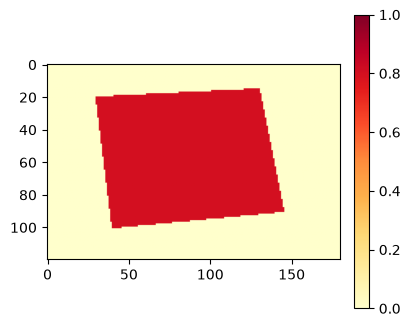

In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

polygon = MarksLand([[20, 30], [15, 130], [90, 145], [100, 40]], shape=image.shape)
heat = polygon.to_heat(.8)
heat.show()

### 2. Use the original heat algebra

`a + b` means maximum (union), `a - b` means minimum (intersection), and `-a` means complement. Subtraction is deliberately **not arithmetic difference**. Scale and power change mask strength; scales clip to [0, 1]. Shapes must match for binary operations.

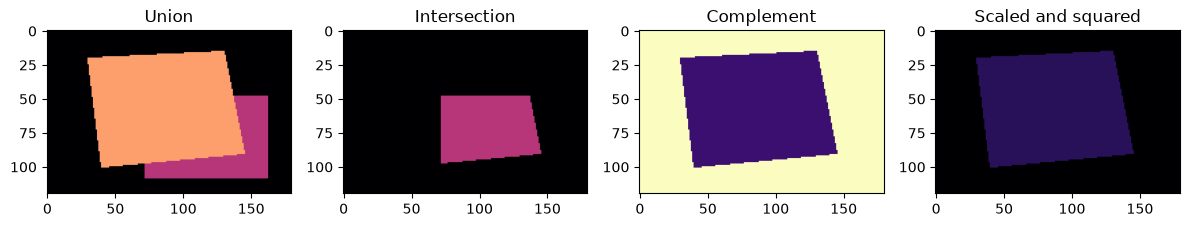

In [3]:
other = SquareMarks.relative(.4, .9, .4, .9, shape=image.shape).to_heat(.5)
heats = [heat + other, heat - other, -heat, (.5 * heat)**2]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, item, title in zip(axes, heats, ['Union', 'Intersection', 'Complement', 'Scaled and squared']):
    ax.imshow(item.get_heat(), vmin=0, vmax=1, cmap='magma'); ax.set_title(title)
plt.tight_layout(); plt.show()

### 3. Apply a color or custom function

`Filter` blends toward an RGB color using `ratio * heat`. A different-size mask is resized on a copy. Alpha channels are preserved. A custom function accepts pixel values and broadcast heat.

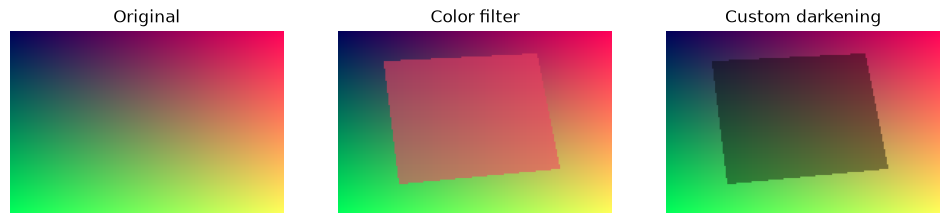

In [4]:
tinted = image.copy().implant_filter(Filter('#f04262', ratio=.7), heat)
custom = Filter().set_function(lambda pixels, weight: pixels*(1-.5*weight))
darkened = image.copy().implant_filter(custom, heat)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, item, title in zip(axes, [image, tinted, darkened], ['Original', 'Color filter', 'Custom darkening']):
    ax.imshow(item.get_image()); ax.set_title(title); ax.axis('off')
plt.show()

## Checks

In [5]:
assert heat.shape == image.shape
assert np.allclose((heat - other).get_heat(), np.minimum(heat.get_heat(), other.get_heat()))
assert np.array_equal(tinted.get_image()[0, 0], image.get_image()[0, 0])
assert not np.array_equal(tinted.get_image()[50, 70], image.get_image()[50, 70])

## Next steps

Continue with tutorial 4 in the [tutorial index](https://github.com/bateni1380/landpy/tree/master/tutorials).